In [2]:
from matplotlib import pyplot as plt
import numpy as np
import random

#### Plotting functions

In [3]:
def draw_line(slope, y_intercept, color='grey', linewidth=0.7, starting=0, ending=8):
    x = np.linspace(starting, ending, 1000)
    plt.plot(x, y_intercept + slope*x, linestyle='-', color=color, linewidth=linewidth)

def plot_points(features, labels):
    X = np.array(features)
    y = np.array(labels)
    plt.scatter(X, y)
    plt.xlabel('number of rooms')
    plt.ylabel('prices')

#### Defining and plotting our dataset

In [4]:
features = np.array([1,2,3,5,6,7])
labels = np.array([155, 197, 244, 356,407,448])

print(features)
print(labels)

[1 2 3 5 6 7]
[155 197 244 356 407 448]


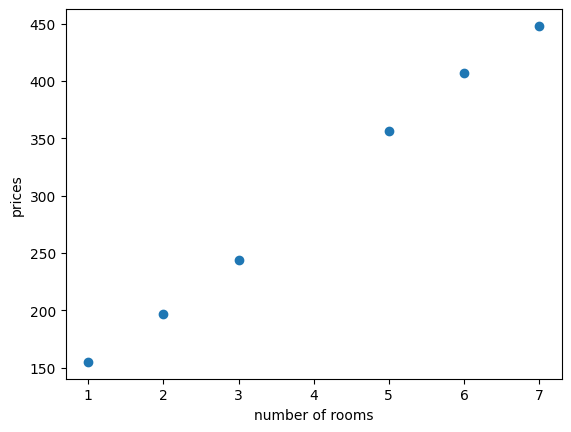

In [5]:
plot_points(features, labels)

#### Coding the tricks

- Simple trick
- Absolute trick
- Square trick

In [9]:
def simple_trick(base_price, price_per_room, num_rooms, price):
    small_random_1 = random.random() * 0.1
    small_random_2 = random.random() * 0.1

    predicted_price = base_price + price_per_room * num_rooms
    if (price > predicted_price) and (num_rooms > 0):
        price_per_room += small_random_1    # add η1 to slope
        base_price += small_random_2    # add η2 to y-intercept
    if price > predicted_price and num_rooms < 0:
        price_per_room -= small_random_1
        base_price += small_random_2
    if price < predicted_price and num_rooms > 0:
        price_per_room -= small_random_1
        base_price -= small_random_2
    if price < predicted_price and num_rooms < 0:
        price_per_room -= small_random_1
        base_price += small_random_2
    return price_per_room, base_price

In [11]:
def square_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    # Calculates the prediction
    predicted_price = (price_per_room * num_rooms) + base_price 
    base_price += learning_rate * (price - predicted_price) # Translates the line
    price_per_room += learning_rate * num_rooms * (price - predicted_price) #  Rotates the line
    predicted_price = (price_per_room * num_rooms) + base_price

    return predicted_price, price_per_room, base_price

In [12]:
def absolute_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    predicted_price = base_price + (price_per_room * num_rooms)
    if (price > predicted_price):
        price_per_room += learning_rate * num_rooms
        base_price += learning_rate
    else:
        price_per_room -= learning_rate * num_rooms
        base_price -= learning_rate
        
    return price_per_room, base_price